# 46500 Probabilistic Methods in Wind Energy
## Mid-term Assignment: Lifetime Damage Accumulation for the Root Section of the Wind Turbine 


s253916 Natalia Slimak

---

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import scipy.optimize as optimize
import seaborn as sns
import os

### Data Exploration & Cleaning

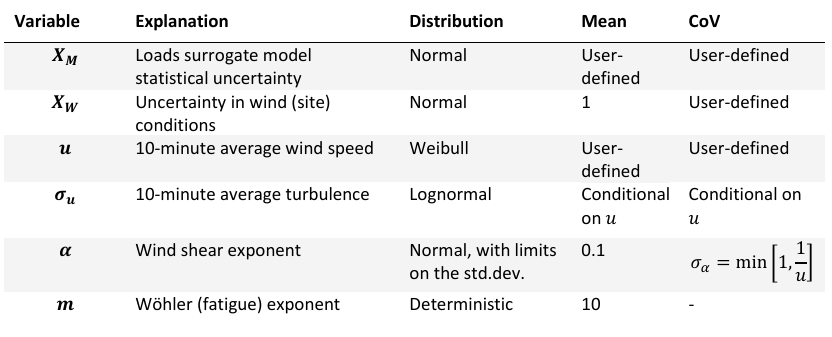

In [3]:
# Load the provided data sets
wind_data = "HovsoreData_Sonic_100m_2004-2013.csv"
del_data = "ML_ExampleDataSet.xlsx"

# Outfput folder location for generated figures
output_figs = "figures/"
os.makedirs(output_figs, exist_ok=True)

# Read the data into pandas DataFrames
df_wind = pd.read_csv(wind_data)
df_del = pd.read_excel(del_data)

# Clean the data
df_wind = df_wind.dropna(subset=["Wsp","TI"])
df_wind = df_wind[(df_wind['Wsp'] > 0) & (df_wind['Wsp'] < 30) & (df_wind['TI'] > 0) & (df_wind['TI'] < 1)]

In [4]:
df_wind

,Timestamp,Wsp,TI,"TI,detrend",MeanDir,MeanTrigDir,StdDir,MinDir,MaxDir
0,200410010000,9.9196,0.0181,0.0145,346.7130,346.7130,0.8440,343.893,349.044
1,200410010020,9.5073,0.0145,0.0116,346.9852,346.9852,0.6518,344.751,348.949
2,200410010030,9.5274,0.0210,0.0195,346.9152,346.9151,0.7949,343.754,350.588
3,200410010040,9.9498,0.0253,0.0195,346.3204,346.3204,0.7549,343.971,349.953
4,200410010050,10.2376,0.0151,0.0134,345.4185,345.4185,0.6362,343.074,348.960
...,...,...,...,...,...,...,...,...,...
439507,201308312310,15.6264,0.0773,0.0589,299.8040,299.8043,2.6738,288.901,309.955
439508,201308312320,13.7150,0.0576,0.0576,298.0319,298.0315,3.2644,288.643,309.245
439509,201308312330,13.4969,0.0797,0.0654,297.7226,297.7242,3.5721,284.827,306.117
439510,201308312340,13.4135,0.1034,0.0901,294.6266,294.6243,3.9459,283.195,310.353


In [5]:
df_del

,Sample_No,U,SigmaU,Alpha,MannL,MannGamma,VeerDeltaPhi
0,1,4.000000,0.100000,-0.650000,7.500000,1.000000,-22.250000
1,2,10.150758,1.208656,-0.139692,48.470634,1.363636,-4.771217
2,3,6.813467,2.261463,0.129071,88.379710,1.727273,-3.981593
3,4,14.500000,0.704260,0.332996,122.142857,2.090909,0.162810
4,5,5.356299,1.776301,1.147039,160.357143,2.454545,2.639008
...,...,...,...,...,...,...,...
9975,9996,15.991490,2.934493,-0.031461,271.543107,3.760740,14.080259
9976,9997,6.111425,0.948102,0.176589,8.454959,4.124377,41.866315
9977,9998,13.326172,2.043617,0.345013,46.669245,4.488013,-6.197441
9978,9999,9.298782,2.830030,0.709374,84.883531,4.851649,-4.457392


### Task 1: Fitting the joint probability distribution ($u$, $\sigma_u$) based on the wind dataset.

NOTES
- $Wsp$: wind speed, modeled as Weibull
- $TI$: turbulence standard deviation, modeled as lognormal conditional on u

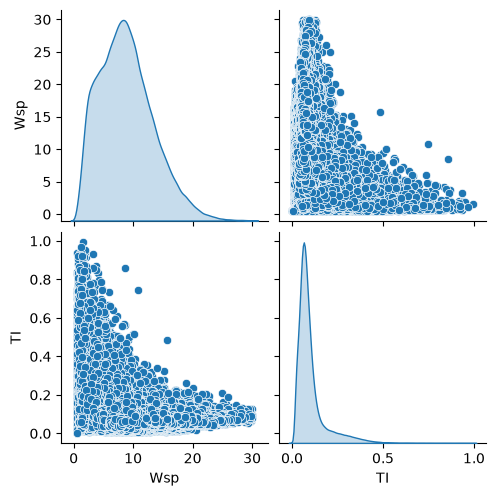

In [6]:
pairplot = sns.pairplot(df_wind[["Wsp", "TI"]], diag_kind="kde")
pairplot.savefig(output_figs + "1.1_pairplot_wind_TI.png", dpi=300)

In [7]:
# Windspeed (U) and turbulence intensity (TI) data
U = df_wind['Wsp'].values
SigmaU = df_wind['TI'].values * U  # Convert TI to standard deviation of wind speed


# === Fit Weibull to u (MLE - Most Likely Estimate) ===
k, _, A = stats.weibull_min.fit(U, floc=0)                  # WEIBULL Distribution fit (floc=0 -> forces the distribution to start at zero)


# === Bin by u, fit Lognormal to sigma_u per bin, then fit a trend curve ===
bins = np.arange(0, 35, 1.0)
centers, means, stds = [], [], []
# lo(wer) and hi(gher) bounds of each bin -> the sigmaU is fitted to the data in that bin
for lo, hi in zip(bins[:-1], bins[1:]):
    s = SigmaU[(U >= lo) & (U < hi)]
    if len(s) < 30:
        continue
    shape, _, scale = stats.lognorm.fit(s, floc=0)          # LOGNORMAL Distribution fit
    centers.append((lo + hi) / 2)
    means.append(scale * np.exp(0.5 * shape**2))
    stds.append(means[-1] * np.sqrt(np.exp(shape**2) - 1))

# Fit a quadratic curve to the mean -> that is what 2 is indicating 
p_mean = np.polyfit(centers, means, 2)
p_std = np.polyfit(centers, stds, 2)
u_max_fit = max(centers)  # clip point to avoid extrapolation blowing up


In [8]:
print(f"Fitted Weibull parameters: k={k:.3f}, A={A:.3f}")
print(f"Fitted Lognormal trend: mean(u)={p_mean}, std(u)={p_std}")

Fitted Weibull parameters: k=2.039, A=9.977
Fitted Lognormal trend: mean(u)=[0.00236736 0.0044493  0.43794619], std(u)=[ 5.95821004e-05 -2.02899499e-03  4.22758049e-01]


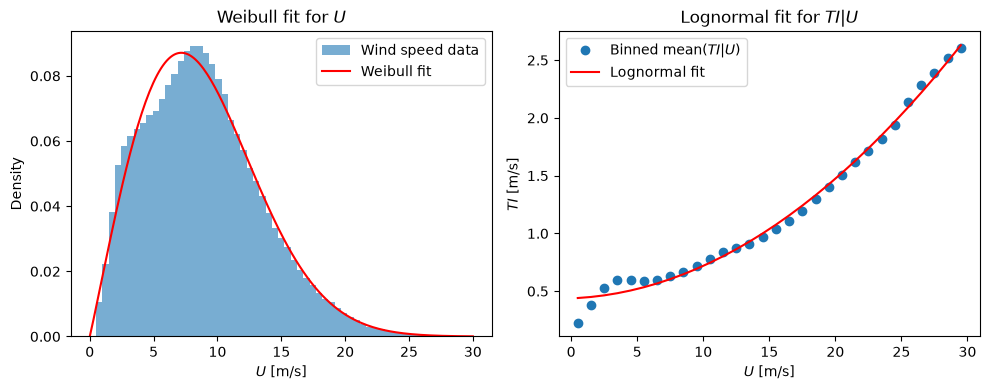

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))

# (a) u marginal: histogram vs fitted Weibull pdf
u_range = np.linspace(0, U.max(), 200)
axs[0].hist(U, bins=60, density=True, alpha=0.6, label='Wind speed data')
axs[0].plot(u_range, stats.weibull_min.pdf(u_range, c=k, scale=A), 'r-', label='Weibull fit')
axs[0].set_xlabel(r'$U$ [m/s]'); axs[0].set_ylabel('Density')
axs[0].set_title(r'Weibull fit for $U$'); axs[0].legend()

# (b) conditional trend: binned mean vs the fitted curve
axs[1].plot(centers, means, 'o', label=r'Binned mean($TI$|$U$)')
axs[1].plot(centers, np.polyval(p_mean, centers), 'r-', label='Lognormal fit')
axs[1].set_xlabel(r'$U$ [m/s]'); axs[1].set_ylabel(r'$TI$ [m/s]')
axs[1].set_title(r'Lognormal fit for $TI$|$U$'); axs[1].legend()

plt.savefig(output_figs + "1.2_weibull_lognormal_fit.png", dpi=300)
plt.tight_layout()
plt.show()

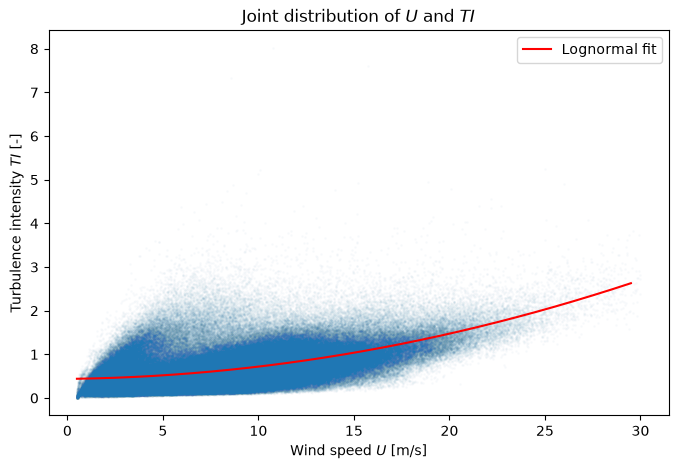

In [13]:
plt.figure(figsize=(8,5))
plt.scatter(U, SigmaU, s=1, alpha=0.02)
plt.xlabel(r"Wind speed $U$ [m/s]")
plt.ylabel(r"Turbulence intensity $TI$ [-]")
plt.title("Joint distribution of $U$ and $TI$")
plt.plot(centers, np.polyval(p_mean, centers), 'r-', label='Lognormal fit')
plt.legend()
plt.savefig(output_figs + "1.3_joint_distribution.png", dpi=300)

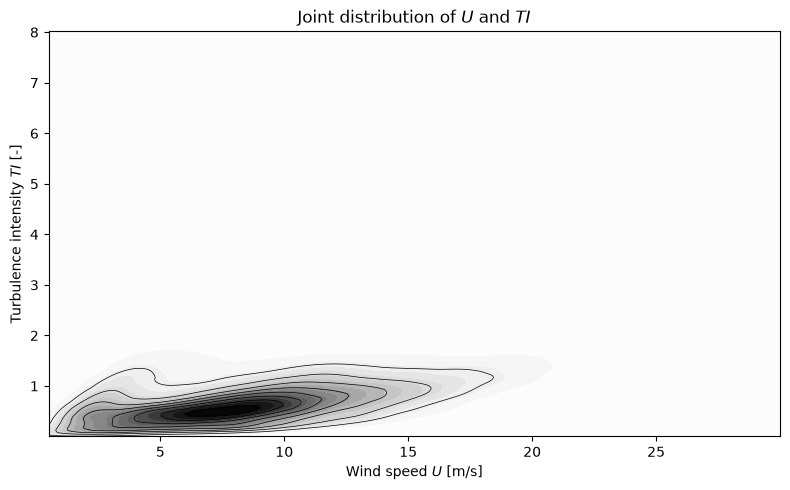

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# --- Prepare data ---
x = U
y = SigmaU

# Optional: keep only reasonable values
mask = (x > 0) & (y > 0)
x = x[mask]
y = y[mask]

# --- Estimate 2D density ---
xy = np.vstack([x, y])
kde = gaussian_kde(xy)

# Grid for plotting
xi = np.linspace(x.min(), x.max(), 200)
yi = np.linspace(y.min(), y.max(), 200)
X, Y = np.meshgrid(xi, yi)
Z = kde(np.vstack([X.ravel(), Y.ravel()])).reshape(X.shape)

# --- Plot ---
fig, ax = plt.subplots(figsize=(8, 5))
levels = np.linspace(Z.min(), Z.max(), 20)
contour = ax.contourf(X, Y, Z, levels=levels, cmap="Greys")
ax.contour(X, Y, Z, levels=10, colors="black", linewidths=0.5)

ax.set_xlabel(r"Wind speed $U$ [m/s]")
ax.set_ylabel(r"Turbulence intensity $TI$ [-]")
ax.set_title("Joint distribution of $U$ and $TI$")
ax.set_xlim(x.min(), x.max())
ax.set_ylim(y.min(), y.max())

plt.tight_layout()
plt.savefig(output_figs + "1.4_joint_distribution_density.png", dpi=300)
plt.show()